In [17]:
#Load the data

import pandas as pd
df = pd.read_csv("PROJECT.csv")
df["SeniorCitizen"] = df["SeniorCitizen"].str.title()   # makes YES/NO match Yes/No
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)    # Yes becomes 1, No becomes 0
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [18]:
#Overall churn rate

df["Churn"].value_counts(normalize=True)

,proportion
Churn,
No,0.734215
Yes,0.265785


In [19]:
#Churn by contract type

(df.groupby("Contract")["ChurnFlag"].mean() * 100).round(1)

,ChurnFlag
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8


In [20]:
#Churn by internet service and payment method

print((df.groupby("InternetService")["ChurnFlag"].mean() * 100).round(1))
print((df.groupby("PaymentMethod")["ChurnFlag"].mean() * 100).round(1))

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: ChurnFlag, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.3
Electronic check             45.3
Mailed check                 19.2
Name: ChurnFlag, dtype: float64


In [21]:
#Churn by how long they have been a customer

df["TenureGroup"] = pd.cut(df["tenure"], [0, 12, 24, 48, 72],
                           labels=["0-12", "13-24", "25-48", "49-72"])
(df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean() * 100).round(1)

,ChurnFlag
TenureGroup,
0-12,47.7
13-24,28.7
25-48,20.4
49-72,9.5


In [22]:
#Monthly charges, left vs stayed

df.groupby("Churn")["MonthlyCharges"].mean().round(2)

,MonthlyCharges
Churn,
No,61.31
Yes,74.44


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")   # clean white look with light grid lines
os.makedirs("images", exist_ok=True)   # makes a folder called "images" to save charts in

In [24]:
def churn_bar(col, title, filename, order=None, rotate=0):
    rate = (df.groupby(col, observed=True)["ChurnFlag"].mean() * 100).round(1)
    rate = rate.reindex(order) if order else rate.sort_values(ascending=False)
    plt.figure(figsize=(7, 4.5))
    ax = sns.barplot(x=rate.index, y=rate.values, color="#E4572E")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.8, f"{v}%", ha="center", fontweight="bold")
    plt.title(title)
    plt.ylabel("Churn rate (%)")
    plt.xlabel("")
    plt.xticks(rotation=rotate)
    plt.ylim(0, rate.max() + 8)
    plt.savefig(f"images/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

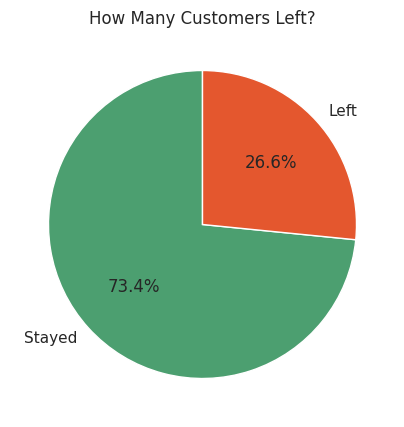

In [25]:
#Chart 1: Stayed vs left

counts = df["Churn"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(counts, labels=["Stayed", "Left"], autopct="%1.1f%%",
        colors=["#4C9F70", "#E4572E"], startangle=90)
plt.title("How Many Customers Left?")
plt.savefig("images/1_churn_overall.png", dpi=150, bbox_inches="tight")
plt.show()

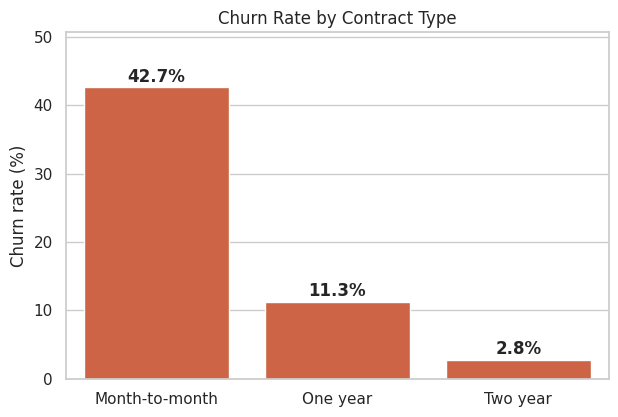

In [26]:
#Chart 2: Contract type

churn_bar("Contract", "Churn Rate by Contract Type", "2_contract.png")

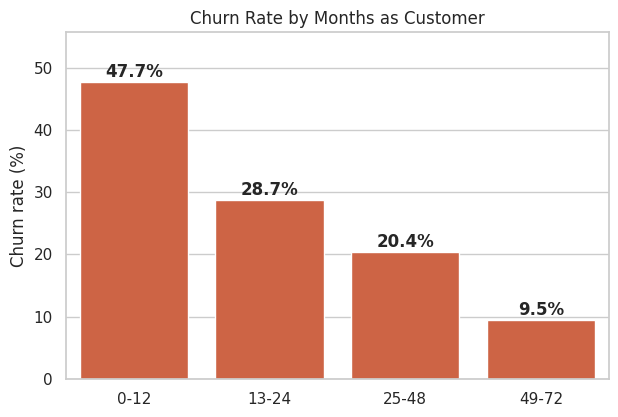

In [27]:
#Chart 3: Months as a customer

churn_bar("TenureGroup", "Churn Rate by Months as Customer", "3_tenure.png",
          order=["0-12", "13-24", "25-48", "49-72"])

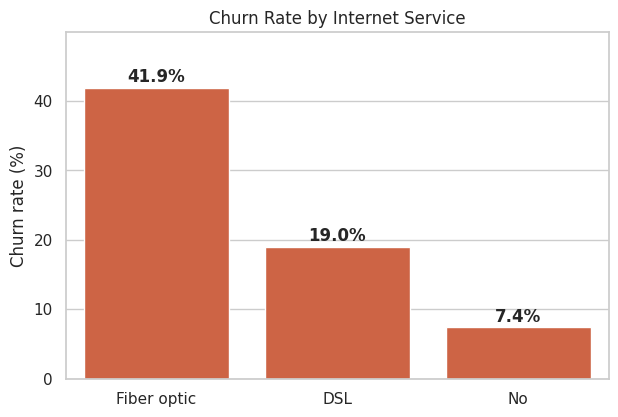

In [28]:
#Chart 4: Internet service

churn_bar("InternetService", "Churn Rate by Internet Service", "4_internet.png")

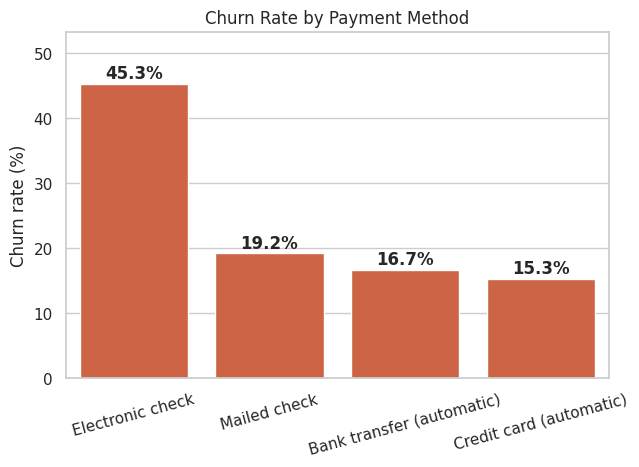

In [29]:
#Chart 5: Payment method

churn_bar("PaymentMethod", "Churn Rate by Payment Method", "5_payment.png", rotate=15)

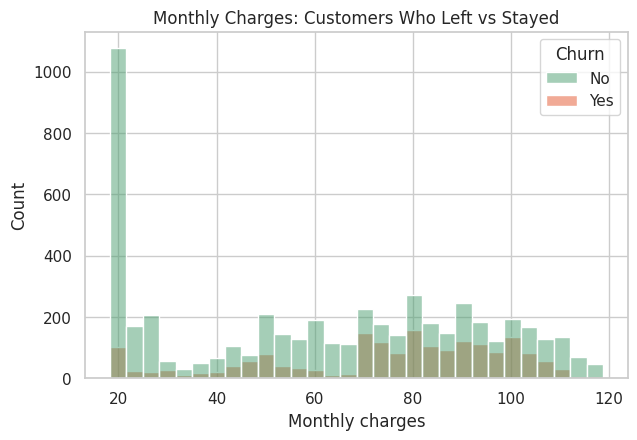

In [30]:
#Chart 6: Monthly charges, left vs stayed

plt.figure(figsize=(7, 4.5))
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30,
             palette={"No": "#4C9F70", "Yes": "#E4572E"})
plt.title("Monthly Charges: Customers Who Left vs Stayed")
plt.xlabel("Monthly charges")
plt.savefig("images/6_monthly_charges.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
from google.colab import files
!zip -r images.zip images
files.download("images.zip")

  adding: images/ (stored 0%)
  adding: images/5_payment.png (deflated 14%)
  adding: images/3_tenure.png (deflated 18%)
  adding: images/1_churn_overall.png (deflated 8%)
  adding: images/2_contract.png (deflated 18%)
  adding: images/4_internet.png (deflated 20%)
  adding: images/6_monthly_charges.png (deflated 16%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
ch = df[df["ChurnFlag"] == 1]
print("Churners on month-to-month:", round((ch["Contract"] == "Month-to-month").mean() * 100, 1))
print("Churners in first 12 months:", round((ch["tenure"] <= 12).mean() * 100, 1))
print("Churners on fiber:", round((ch["InternetService"] == "Fiber optic").mean() * 100, 1))
print("Churners on electronic check:", round((ch["PaymentMethod"] == "Electronic check").mean() * 100, 1))
print("Share of monthly revenue lost:", round(ch["MonthlyCharges"].sum() / df["MonthlyCharges"].sum() * 100, 1))

combo = df[(df["Contract"] == "Month-to-month") &
           (df["InternetService"] == "Fiber optic") &
           (df["PaymentMethod"] == "Electronic check")]
print("Combo group size:", len(combo), "churn %:", round(combo["ChurnFlag"].mean() * 100, 1))

Churners on month-to-month: 88.6
Churners in first 12 months: 55.5
Churners on fiber: 69.4
Churners on electronic check: 57.3
Share of monthly revenue lost: 30.5
Combo group size: 1307 churn %: 60.4


In [33]:
# Preparing Data

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

y = (df["Churn"] == "Yes").astype(int)                 # what we want to predict
X = df.drop(columns=["customerID", "Churn", "ChurnFlag", "TenureGroup"])   # the clues
X = pd.get_dummies(X, drop_first=True)                 # turn words into 0/1 columns

In [34]:
#Split and Train

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_s, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [35]:
#Test

pred = model.predict(X_test_s)
prob = model.predict_proba(X_test_s)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 3))
print(classification_report(y_test, pred, target_names=["Stayed", "Left"]))
print(confusion_matrix(y_test, pred))

Accuracy: 0.726
ROC AUC: 0.835
              precision    recall  f1-score   support

      Stayed       0.91      0.70      0.79      1033
        Left       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

[[724 309]
 [ 76 298]]


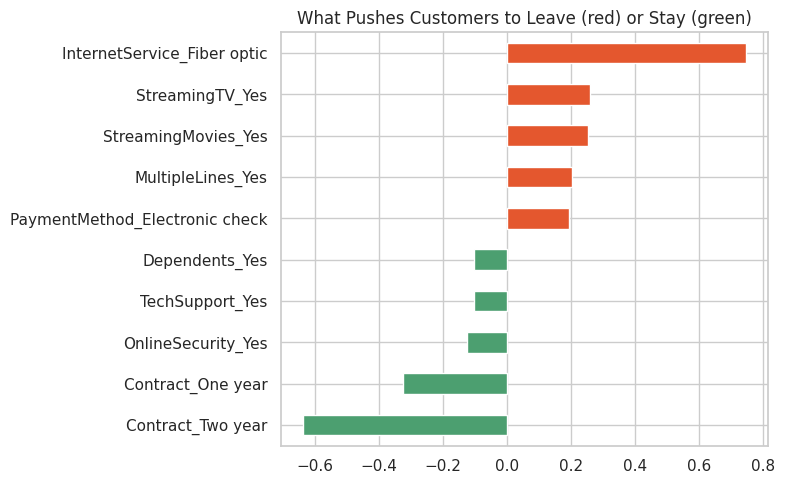

In [36]:
#What drives Churn

coef = pd.Series(model.coef_[0], index=X.columns)
coef = coef.drop(["tenure", "MonthlyCharges", "TotalCharges"])   # these three overlap, so skip them
top = pd.concat([coef.sort_values().head(5), coef.sort_values().tail(5)])

top.plot(kind="barh", color=["#4C9F70" if v < 0 else "#E4572E" for v in top], figsize=(8, 5))
plt.title("What Pushes Customers to Leave (red) or Stay (green)")
plt.tight_layout()
plt.savefig("images/7_drivers.png", dpi=150)
plt.show()

In [37]:
#Risk List

risk = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"],
    "churn_probability": prob.round(2)
}).sort_values("churn_probability", ascending=False)

risk.head(10)

,customerID,churn_probability
3374,5178-LMXOP,0.93
3154,5150-ITWWB,0.93
2626,6861-XWTWQ,0.92
931,4750-ZRXIU,0.92
4577,1069-XAIEM,0.92
3721,9057-SIHCH,0.92
2792,6023-YEBUP,0.92
581,2865-TCHJW,0.92
2511,8245-UMPYT,0.91
352,4115-NZRKS,0.91
